In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
%pip install -q transformers datasets peft accelerate scikit-learn


In [3]:
import torch
import transformers
import datasets
import peft
import sklearn

print("All libraries imported successfully!")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))

All libraries imported successfully!
Transformers: 5.22.1
Datasets: 4.8.5
PEFT: 0.21.2
GPU: Tesla T4


In [4]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")

print(dataset)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [5]:
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))
print("Testing examples:", len(dataset["test"]))

print("\nFirst training example:")
print(dataset["train"][0])

Training examples: 16000
Validation examples: 2000
Testing examples: 2000

First training example:
{'text': 'i didnt feel humiliated', 'label': 0}


In [6]:
from collections import Counter

label_names = dataset["train"].features["label"].names

label_counts = Counter(dataset["train"]["label"])

print("Emotion distribution in training data:\n")

for label_id, count in sorted(label_counts.items()):
    emotion = label_names[label_id]
    percentage = (count / len(dataset["train"])) * 100

    print(f"{emotion:10s}: {count:5d} ({percentage:.2f}%)")

Emotion distribution in training data:

sadness   :  4666 (29.16%)
joy       :  5362 (33.51%)
love      :  1304 (8.15%)
anger     :  2159 (13.49%)
fear      :  1937 (12.11%)
surprise  :   572 (3.57%)


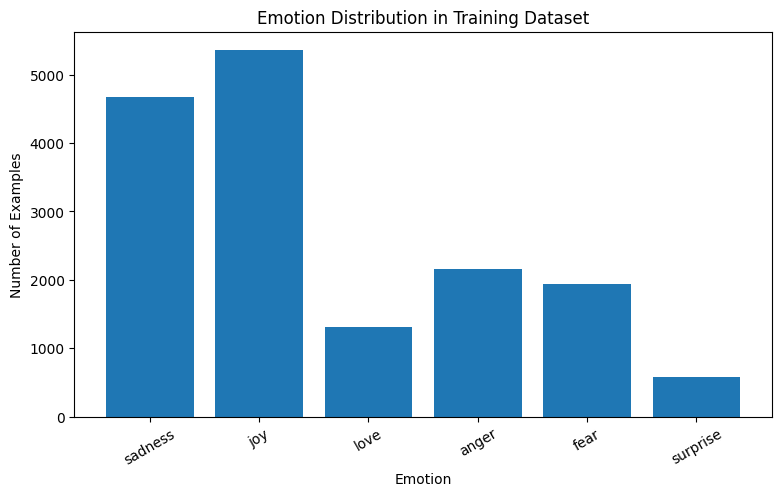

In [7]:
import matplotlib.pyplot as plt

emotions = [label_names[i] for i in range(len(label_names))]
counts = [label_counts[i] for i in range(len(label_names))]

plt.figure(figsize=(9, 5))
plt.bar(emotions, counts)
plt.title("Emotion Distribution in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Examples")
plt.xticks(rotation=30)
plt.show()

In [8]:
from transformers import AutoTokenizer

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)
print("Model:", model_name)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 151643
Model: Qwen/Qwen2.5-0.5B-Instruct


In [9]:
import torch
from transformers import AutoModelForSequenceClassification

# Define emotion labels
label_names = dataset["train"].features["label"].names

id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in enumerate(label_names)}

# Configure tokenizer padding
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# Load the sequence classification model
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=6,
    id2label=id2label,
    label2id=label2id,
    problem_type="single_label_classification",
    torch_dtype=torch.float16,
    device_map="auto"
)

model.config.pad_token_id = tokenizer.pad_token_id

print("Model loaded successfully!")
print("Number of labels:", model.config.num_labels)
print("Emotion labels:", model.config.id2label)
print("Model device:", model.device)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Number of labels: 6
Emotion labels: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
Model device: cuda:0


In [10]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

print("Dataset tokenization completed!")

print("\nTokenized training example:")
print(tokenized_dataset["train"][0])

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset tokenization completed!

Tokenized training example:
{'text': 'i didnt feel humiliated', 'label': 0, 'input_ids': [72, 47607, 2666, 2784, 53773], 'attention_mask': [1, 1, 1, 1, 1]}


In [13]:
from peft import LoraConfig, TaskType, get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"]
)

model = get_peft_model(model, lora_config)

print("LoRA adapters applied successfully!")

model.print_trainable_parameters()

LoRA adapters applied successfully!
trainable params: 546,048 || all params: 494,584,192 || trainable%: 0.1104


In [12]:
%pip uninstall -y torchao


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [14]:
import torch
import peft

print("PyTorch:", torch.__version__)
print("PEFT:", peft.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
PEFT: 0.21.2
GPU available: True


In [15]:
from peft import LoraConfig, TaskType, get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"]
)

model = get_peft_model(model, lora_config)

print("LoRA adapters applied successfully!")
model.print_trainable_parameters()

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


LoRA adapters applied successfully!
trainable params: 546,048 || all params: 494,584,192 || trainable%: 0.1104


In [16]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

label_names = dataset["train"].features["label"].names

id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in enumerate(label_names)}

tokenizer = AutoTokenizer.from_pretrained(model_name)

tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=6,
    id2label=id2label,
    label2id=label2id,
    problem_type="single_label_classification",
    dtype=torch.float16,
    device_map="auto"
)

model.config.pad_token_id = tokenizer.pad_token_id

print("Model loaded successfully!")
print("Number of labels:", model.config.num_labels)
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Number of labels: 6
GPU: Tesla T4


In [17]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

print("Data collator created successfully!")

Data collator created successfully!


In [18]:
tokenized_dataset = tokenized_dataset.remove_columns(["text"])

print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 2000
    })
})


In [19]:
sample_batch = data_collator(
    [tokenized_dataset["train"][i] for i in range(8)]
)

for key, value in sample_batch.items():
    print(key, value.shape)

input_ids torch.Size([8, 24])
attention_mask torch.Size([8, 24])
labels torch.Size([8])


In [20]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

print("Evaluation metrics configured!")

Evaluation metrics configured!


In [21]:
from transformers import Trainer, TrainingArguments

model.config.use_cache = False

training_args = TrainingArguments(
    output_dir="./qwen-emotion-lora",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    fp16=True,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    report_to="none",
    save_total_limit=2,
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [22]:
baseline_results = trainer.predict(tokenized_dataset["test"])

print("BASE MODEL BASELINE")
print("Accuracy:", baseline_results.metrics["test_accuracy"])
print("Macro F1:", baseline_results.metrics["test_macro_f1"])

BASE MODEL BASELINE
Accuracy: 0.138
Macro F1: 0.120183346699572


In [23]:
import torch
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=6,
    id2label=id2label,
    label2id=label2id,
    problem_type="single_label_classification",
    dtype=torch.float32,
    device_map="auto"
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

print("Base model reloaded in FP32!")
print("Model dtype:", next(model.parameters()).dtype)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Base model reloaded in FP32!
Model dtype: torch.float32


In [24]:
from peft import LoraConfig, TaskType, get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"]
)

model = get_peft_model(model, lora_config)

print("LoRA adapters applied successfully!")
model.print_trainable_parameters()

LoRA adapters applied successfully!
trainable params: 546,048 || all params: 494,584,192 || trainable%: 0.1104


In [25]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./qwen-emotion-lora",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    fp16=True,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    report_to="none",
    save_total_limit=2,
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer recreated successfully!")

Trainer recreated successfully!


In [30]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.541369,0.233430,0.917000,0.890726
2,0.290128,0.161310,0.930000,0.899968


In [26]:
# Evaluate the best fine-tuned model on the test set
test_results = trainer.predict(tokenized_dataset["test"])

print("FINE-TUNED MODEL — TEST RESULTS")
print("Test Accuracy:", test_results.metrics["test_accuracy"])
print("Test Macro F1:", test_results.metrics["test_macro_f1"])

FINE-TUNED MODEL — TEST RESULTS
Test Accuracy: 0.119
Test Macro F1: 0.10137994202376621


In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Get predictions and actual labels
predictions = np.argmax(test_results.predictions, axis=-1)
true_labels = test_results.label_ids

# Classification report
print("CLASSIFICATION REPORT")
print(
    classification_report(
        true_labels,
        predictions,
        target_names=[id2label[i] for i in range(6)],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(true_labels, predictions)

print("\nCONFUSION MATRIX")
print(pd.DataFrame(
    cm,
    index=[id2label[i] for i in range(6)],
    columns=[id2label[i] for i in range(6)]
))

# Find three high-confidence incorrect predictions
probabilities = np.exp(test_results.predictions - np.max(
    test_results.predictions, axis=1, keepdims=True
))
probabilities = probabilities / probabilities.sum(axis=1, keepdims=True)

wrong_indices = np.where(predictions != true_labels)[0]
wrong_indices = sorted(
    wrong_indices,
    key=lambda i: probabilities[i].max(),
    reverse=True
)

print("\nTHREE FAILURE EXAMPLES")

for i in wrong_indices[:3]:
    print("\nText:", dataset["test"][i]["text"])
    print("Actual emotion:", id2label[int(true_labels[i])])
    print("Predicted emotion:", id2label[int(predictions[i])])
    print("Prediction confidence:", round(float(probabilities[i].max()), 4))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     sadness       0.41      0.20      0.27       581
         joy       0.33      0.00      0.00       695
        love       0.10      0.40      0.16       159
       anger       0.00      0.00      0.00       275
        fear       0.11      0.09      0.10       224
    surprise       0.04      0.55      0.08        66

    accuracy                           0.12      2000
   macro avg       0.17      0.21      0.10      2000
weighted avg       0.26      0.12      0.11      2000


CONFUSION MATRIX
          sadness  joy  love  anger  fear  surprise
sadness       117    1   198      5    54       206
joy            64    1   203      1    72       354
love           13    0    63      1    17        65
anger          50    0    86      0    18       121
fear           34    1    80      0    21        88
surprise        6    0    16      0     8        36

THREE FAILURE EXAMPLES

Text: i was lucky enough to 